In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


The camera image is stored as a 512 × 512 matrix of pixel intensities. Converting it to float allows calculations without the wraparound that can happen with uint8 values.

In [2]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("U:", U.shape, "s:", s.shape, "Vt:", Vt.shape)
A_back = U @ np.diag(s) @ Vt
print("Rebuilt correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.538058652135078e-11


The SVD factors the image matrix into U, Σ, and V transpose. The array s contains the singular values, which become the diagonal of Σ. Multiplying the factors reconstructs the image, with a small error from floating-point rounding.

First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


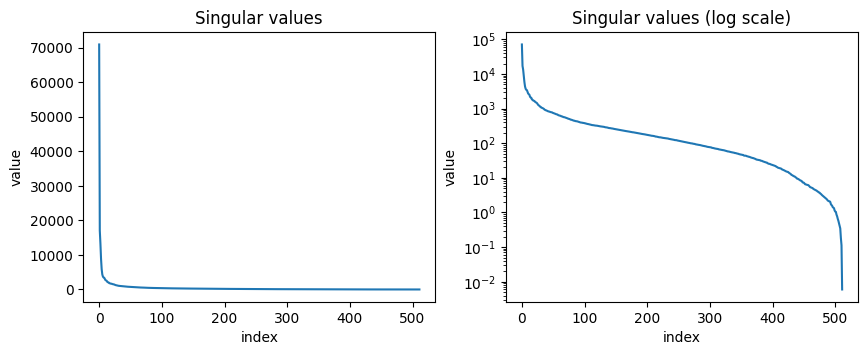

In [3]:
print("First five:", np.round(s[:5], 1))
print("50th, 200th, last:", round(s[49], 1),
      round(s[199], 1), round(s[-1], 3))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title="Singular values", xlabel="index", ylabel="value")
ax2.semilogy(s)
ax2.set(title="Singular values (log scale)",
        xlabel="index", ylabel="value")
plt.show()

The singular values decrease from largest to smallest. Larger singular
values contribute more to the image, so keeping the first few can preserve
its main features. The log-scale plot makes the smaller singular values
easier to see.

In [4]:
def rank_k_approx(A, k):
    """Return the rank-k SVD approximation of A."""
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

The function keeps the first k columns of U, the first k singular values, and the first k rows of V transpose. Multiplying these truncated factors produces an approximation of A with rank at most k.

In [5]:
print("rank of A_10:", np.linalg.matrix_rank(rank_k_approx(A, 10)))
print("k = 512 gives A back?", np.allclose(rank_k_approx(A, 512), A))
stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print("singular values of stripes:",
      np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


The checks show that the rank-10 approximation has rank 10 and that keeping
all 512 components reconstructs the original image. The stripes matrix
has only one nonzero singular value because it is an outer product of two
nonzero vectors and therefore has rank 1.

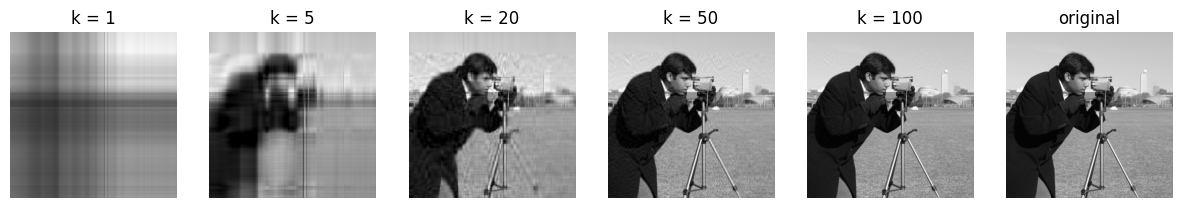

In [6]:
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))

for ax, k in zip(axes, ks):
    Ak = np.clip(rank_k_approx(A, k), 0, 255)
    ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("original")
axes[-1].axis("off")
plt.show()

As k increases, the approximation preserves more detail and looks closer
to the original image. np.clip keeps the displayed pixel values between
0 and 255, while using the same vmin and vmax makes the brightness
comparison consistent. The Eckart–Young theorem states that the truncated
SVD gives the smallest Frobenius error among approximations of rank at
most k.

In [7]:
M = np.array([[3, 0],
              [4, 5]], dtype=float)

#single vals from eigenvalues of M^T M
MtM = M.T @ M
eigvals = np.linalg.eigvalsh(MtM)[::-1]   #eigvalsh ret. smallest so flip
print("M^T M =\n", MtM)
print("eigenvalues:", eigvals)
print("singular values (by hand):", np.sqrt(eigvals))

#check np.linalg.svd
U, S, Vt = np.linalg.svd(M)
print("singular values (svd):", S)
print("Match?", np.allclose(S, np.sqrt(eigvals)))

#flip u1 and v1 only
u1 = U[:, [0]]
v1 = Vt[[0], :].T
print("u1 v1^T =\n", u1 @ v1.T)
print("(-u1)(-v1)^T =\n", (-u1) @ (-v1).T)
print("Same?", np.allclose(u1 @ v1.T, (-u1) @ (-v1).T))

M^T M =
 [[25. 20.]
 [20. 25.]]
eigenvalues: [45.  5.]
singular values (by hand): [6.70820393 2.23606798]
singular values (svd): [6.70820393 2.23606798]
Match? True
u1 v1^T =
 [[0.2236068  0.2236068 ]
 [0.67082039 0.67082039]]
(-u1)(-v1)^T =
 [[0.2236068  0.2236068 ]
 [0.67082039 0.67082039]]
Same? True


1. Because every entry of u1v1^T is a product uivj and flipping both vectors just turns each one into (-ui)(-vj). The two negatives cancel so then every entry comes out the same. The reasons the signs can flip because an eigenvector only gives you a direction. If v1 works -v1 does and NumPy just picks whichever one. Since u1 is made from v1 it flips right along with it. They always move together so M never changes.

In [8]:
error = np.linalg.norm(A - rank_k_approx(A, 20))
predicted_error = np.sqrt(np.sum(s[20:] ** 2))

print("Actual error:", error)
print("Error from singular values:", predicted_error)
print("Do they agree?", np.isclose(error, predicted_error))

Actual error: 7699.9091419681245
Error from singular values: 7699.9091419681245
Do they agree? True


2. Both of the calculations have the same error, which is approximately 7699.91. This matches the formula with the singular values left out of the the approximation. We start at s[20:] since Python starts at 0. The first 20 singular values are 0 to 19, therefore we leave out index 20.

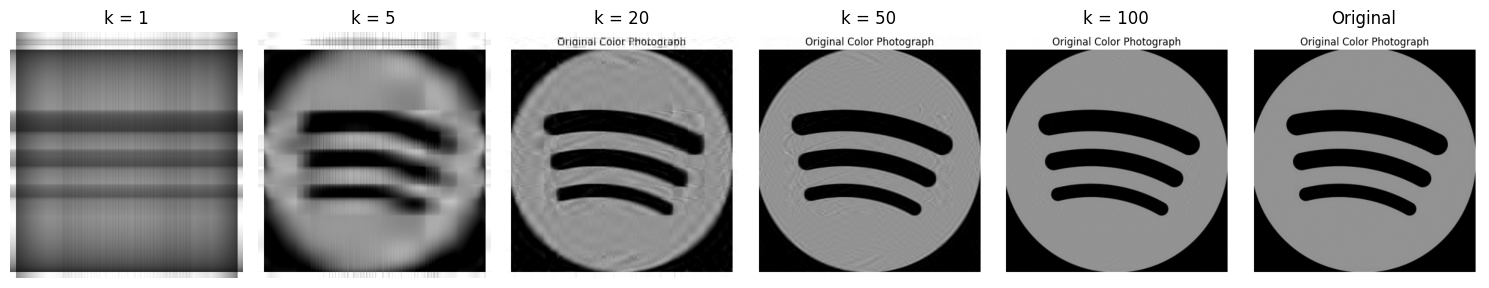

In [9]:
from PIL import Image

img = Image.open("/content/Spotify.png").convert("L")
img.thumbnail((800, 800))
P = np.array(img).astype(float)

ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for ax, k in zip(axes, ks):
    Pk = np.clip(rank_k_approx(P, k), 0, 255)
    ax.imshow(Pk, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(P, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("Original")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

3. The smallest k value I tested was 5. The image is blurry, but you can still see the lines that make up the spotify logo. When k increases, the picture becomes clearer and closer to the original one.